# Heart Disease Prediction System — Complete Project
**Course:** AI2002 – Artificial Intelligence | **Instructor:** Bushra Rashid | **Institution:** FAST-NUCES

| Name | Roll No |
|---|---|
| Muhammad Umar Bin Naeem | 24L-0582 |
| Waleed Bin Omer | 24L-0571 |
| Anas Irfan | 24L-0747 |

---
## 1. Dataset Description and Features

**Dataset:** Merged UCI Heart Disease Dataset (extended Cleveland variant)  
**Source:** UCI Machine Learning Repository — https://archive.ics.uci.edu/ml/datasets/heart+disease  
**Domain:** Medical / Cardiovascular Health  
**Task:** Binary Classification — predict presence (1) or absence (0) of heart disease  
**Size:** 2,181 records × 14 columns

| Feature | Type | Description |
|---|---|---|
| age | Numerical | Patient age in years |
| sex | Categorical | 1 = Male, 0 = Female |
| cp | Categorical | Chest pain type: 0=Typical Angina, 1=Atypical, 2=Non-anginal, 3=Asymptomatic |
| trestbps | Numerical | Resting blood pressure (mm Hg) |
| chol | Numerical | Serum cholesterol (mg/dl) |
| fbs | Categorical | Fasting blood sugar > 120 mg/dl (1=True, 0=False) |
| restecg | Categorical | Resting ECG results (0–2) |
| thalachh | Numerical | Maximum heart rate achieved |
| exang | Categorical | Exercise-induced angina (1=Yes, 0=No) |
| oldpeak | Numerical | ST depression induced by exercise |
| slope | Categorical | Slope of peak exercise ST segment (0–2) |
| ca | Numerical | Number of major vessels (0–4) colored by fluoroscopy |
| thal | Categorical | Thalassemia type (1–3) |
| target | Categorical | **Target**: 1 = Disease, 0 = No Disease |

---
## 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

print('All libraries imported successfully.')

All libraries imported successfully.


---
## 3. Preprocessing

### 3.1 Load Data

In [2]:
df = pd.read_csv('raw_merged_heart_dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (2181, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 3.2 Handle Missing Values

In [3]:
# Dataset uses '?' as missing value placeholder
df.replace('?', np.nan, inplace=True)

cols_to_fix = ['trestbps','chol','fbs','restecg','thalachh','exang','slope','ca','thal']
for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
age           0
sex           0
cp            0
trestbps      1
chol         23
fbs           8
restecg       1
thalachh      1
exang         1
oldpeak       0
slope       190
ca          291
thal        266
target        0
dtype: int64


In [4]:
# Binary columns → mode imputation | Continuous/ordinal → median imputation
for col in ['fbs', 'restecg', 'exang']:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in ['trestbps','chol','thalachh','slope','ca','thal']:
    df[col] = df[col].fillna(df[col].median())

print('Missing values after imputation:', df.isnull().sum().sum())

Missing values after imputation: 0


### 3.3 Data Type Conversion

In [5]:
int_cols = ['trestbps','chol','fbs','restecg','thalachh','exang','slope','ca','thal']
for col in int_cols:
    df[col] = df[col].astype(int)

print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


### 3.4 Outlier Detection & Capping (IQR)

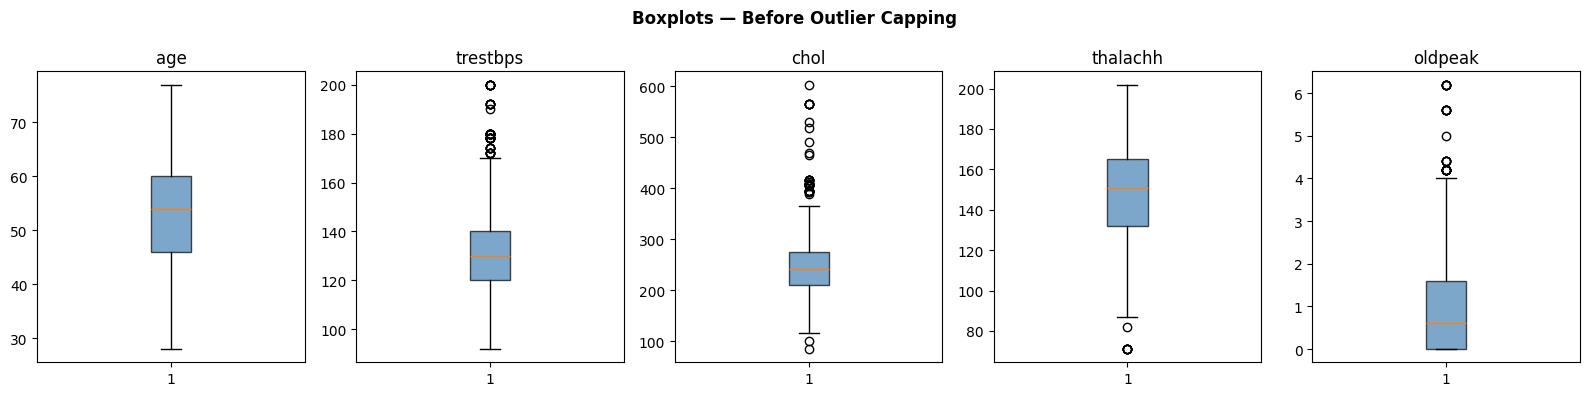

Outliers capped via IQR method.


In [6]:
continuous = ['age', 'trestbps', 'chol', 'thalachh', 'oldpeak']

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, col in enumerate(continuous):
    axes[i].boxplot(df[col], patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.7))
    axes[i].set_title(col)
plt.suptitle('Boxplots — Before Outlier Capping', fontweight='bold')
plt.tight_layout()
plt.show()

for col in continuous:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(lower=Q1 - 1.5*IQR, upper=Q3 + 1.5*IQR)

print('Outliers capped via IQR method.')

### 3.5 Dimensionality & Descriptive Statistics

In [7]:
print(f'Shape: {df.shape}  →  {df.shape[0]} samples, {df.shape[1]} features')
print()
print('Target distribution:')
print(df['target'].value_counts())

Shape: (2181, 14)  →  2181 samples, 14 features

Target distribution:
target
0    1099
1    1082
Name: count, dtype: int64


In [8]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
count,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.0
mean,53.48,0.69,1.25,131.32,245.98,0.14,0.55,148.10,0.33,0.98,1.41,0.63,2.62,0.5
std,9.19,0.46,1.12,16.56,48.49,0.34,0.63,23.21,0.47,1.09,0.60,0.98,1.24,0.5
min,28.00,0.00,0.00,92.00,113.50,0.00,0.00,82.50,0.00,0.00,0.00,0.00,0.00,0.0
25%,46.00,0.00,0.00,120.00,211.00,0.00,0.00,132.00,0.00,0.00,1.00,0.00,2.00,0.0
50%,54.00,1.00,1.00,130.00,242.00,0.00,0.00,151.00,0.00,0.60,1.00,0.00,2.00,0.0
75%,60.00,1.00,2.00,140.00,276.00,0.00,1.00,165.00,1.00,1.60,2.00,1.00,3.00,1.0
max,77.00,1.00,3.00,170.00,373.50,1.00,2.00,202.00,1.00,4.00,3.00,4.00,7.00,1.0


---
## 4. Data Visualisation

### 4.1 Numerical Features — Histograms

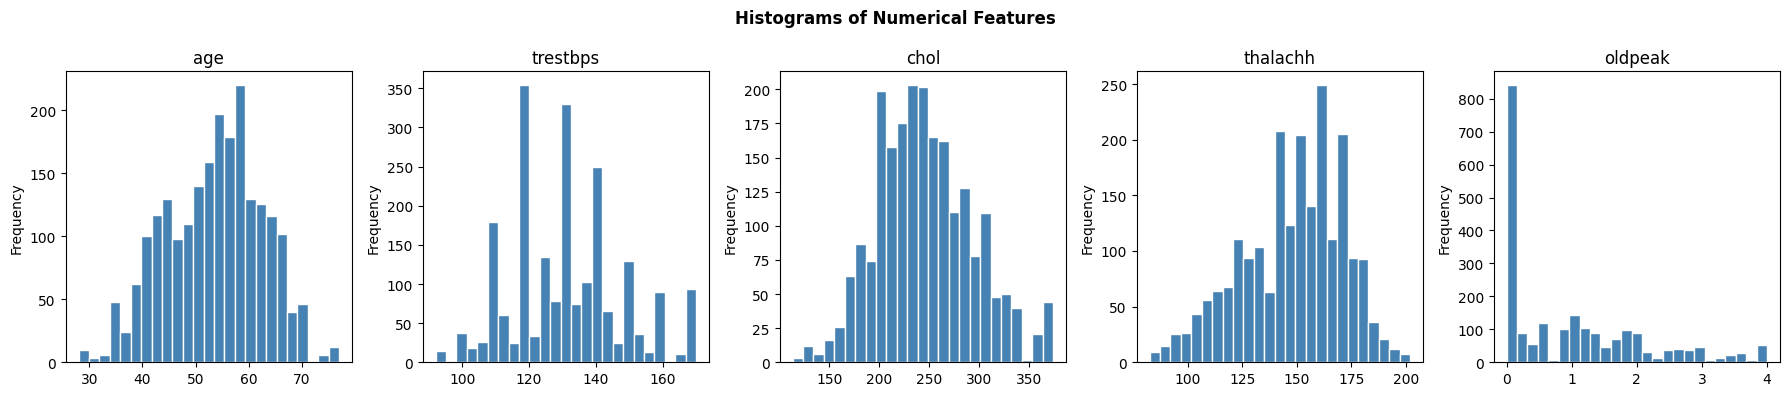

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(continuous):
    axes[i].hist(df[col], bins=25, color='steelblue', edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Numerical Features', fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2 Categorical Features — Bar Charts

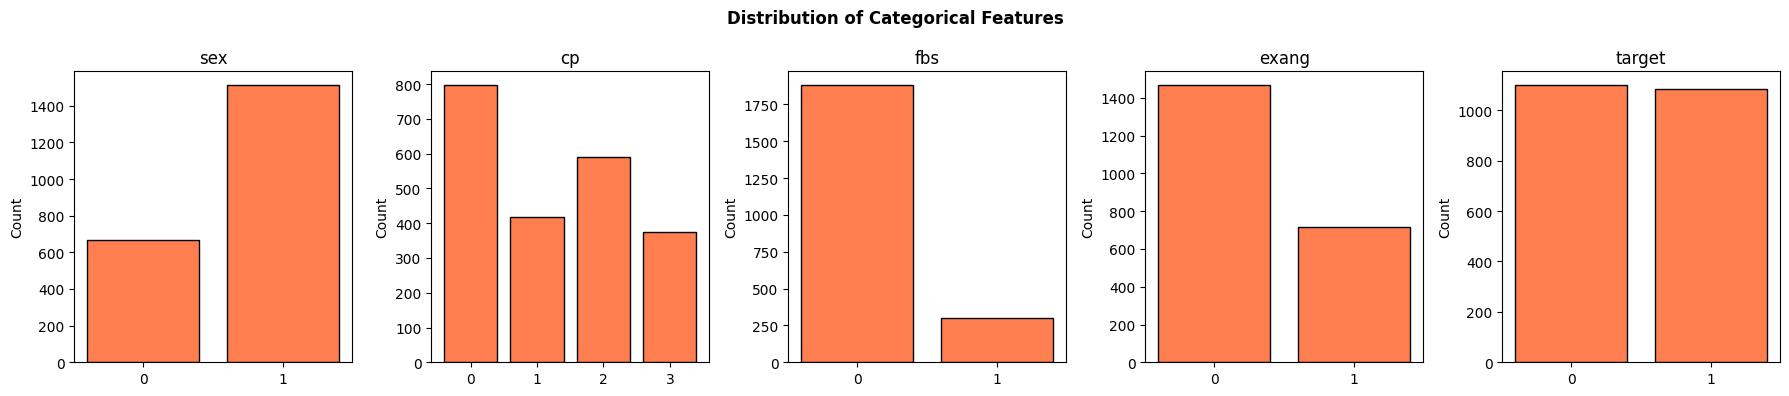

In [10]:
cat_cols = ['sex', 'cp', 'fbs', 'exang', 'target']

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(cat_cols):
    counts = df[col].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color='coral', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_ylabel('Count')
plt.suptitle('Distribution of Categorical Features', fontweight='bold')
plt.tight_layout()
plt.show()

### 4.3 Scatter Plots

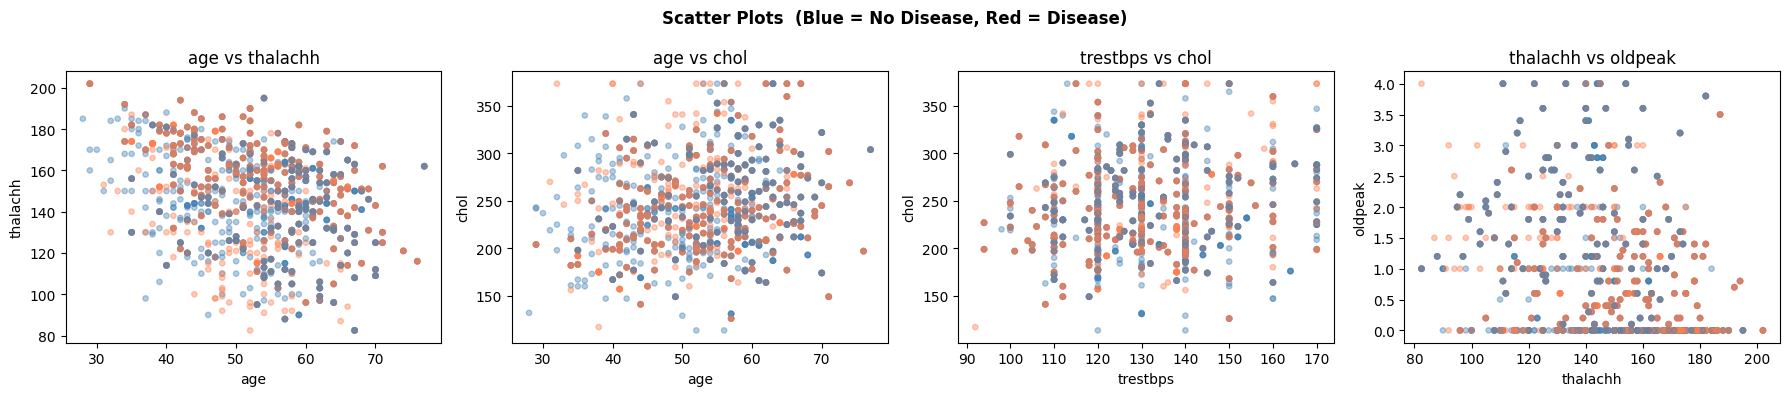

In [11]:
pairs = [('age','thalachh'), ('age','chol'), ('trestbps','chol'), ('thalachh','oldpeak')]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, (x, y) in enumerate(pairs):
    colors = df['target'].map({0:'steelblue', 1:'coral'})
    axes[i].scatter(df[x], df[y], c=colors, alpha=0.4, s=15)
    axes[i].set_xlabel(x)
    axes[i].set_ylabel(y)
    axes[i].set_title(f'{x} vs {y}')
plt.suptitle('Scatter Plots  (Blue = No Disease, Red = Disease)', fontweight='bold')
plt.tight_layout()
plt.show()

### 4.4 Pair Plot

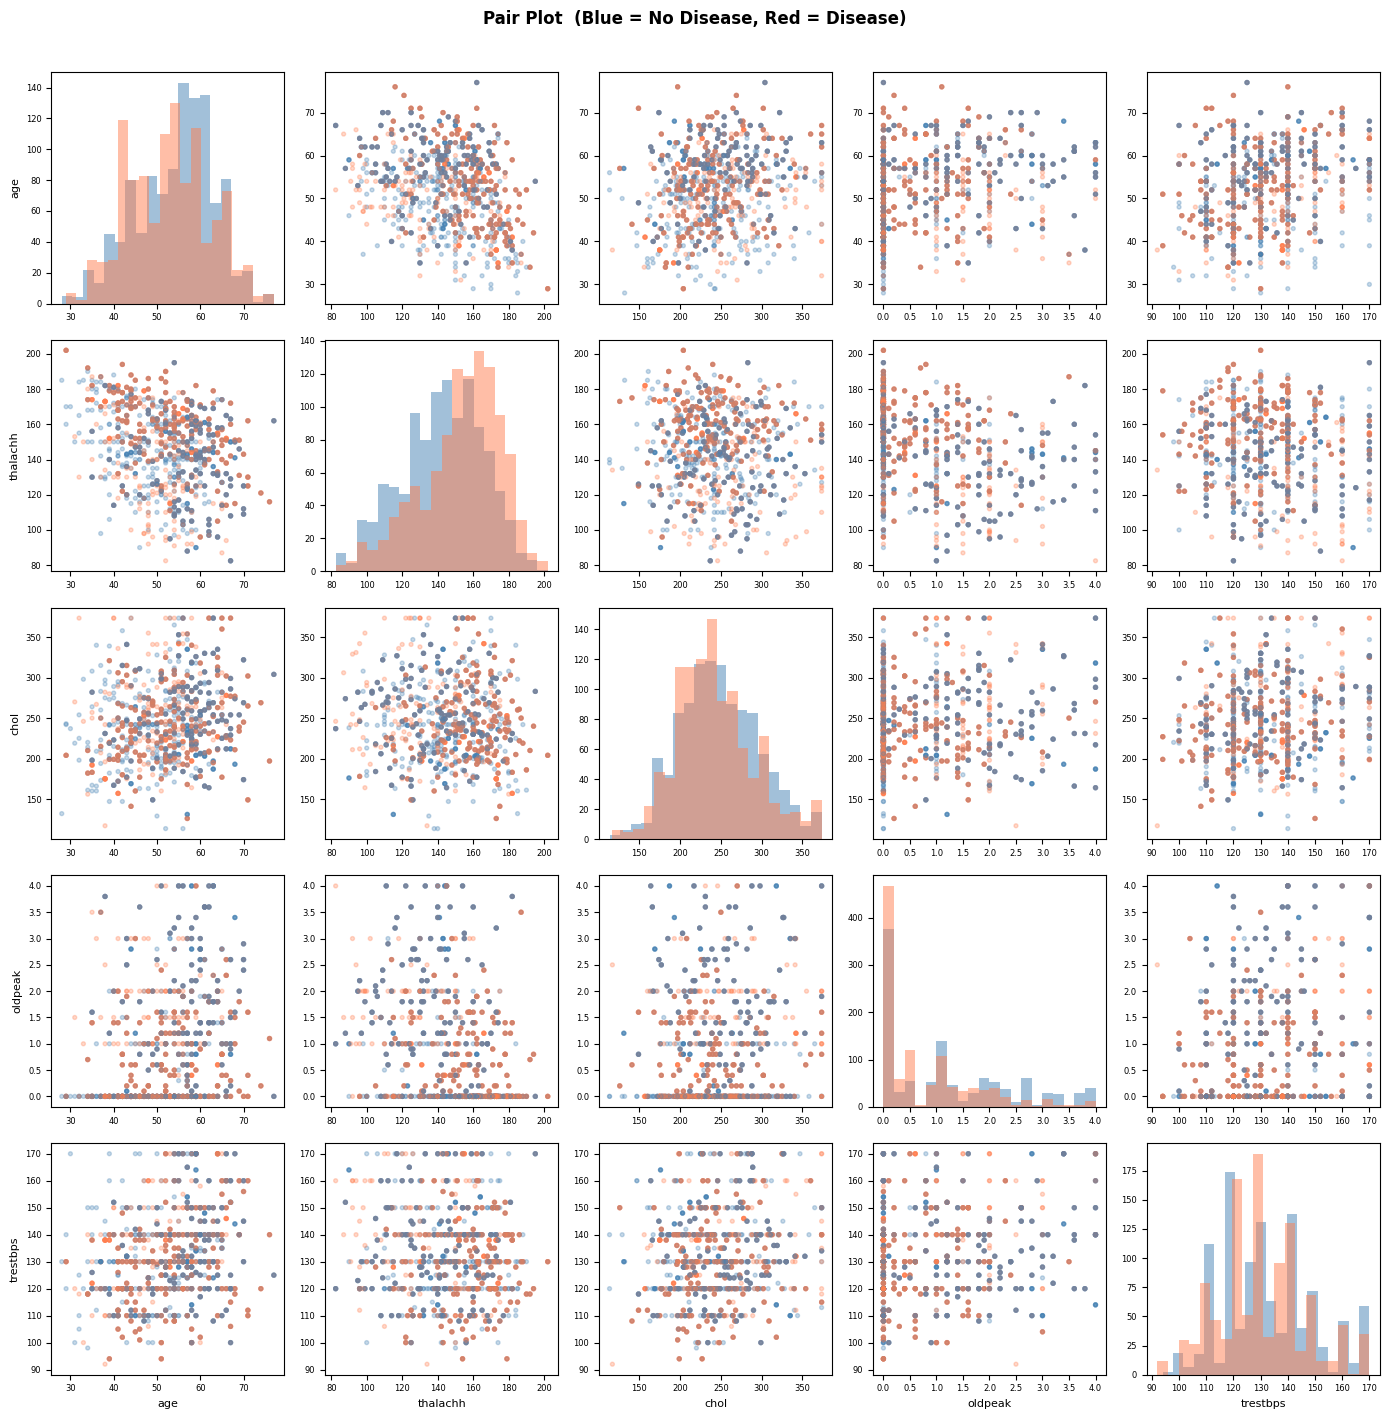

In [12]:
pair_cols = ['age', 'thalachh', 'chol', 'oldpeak', 'trestbps']
colors = df['target'].map({0: 'steelblue', 1: 'coral'})
n = len(pair_cols)

fig, axes = plt.subplots(n, n, figsize=(14, 14))
for i, col_y in enumerate(pair_cols):
    for j, col_x in enumerate(pair_cols):
        ax = axes[i][j]
        if i == j:
            for label, color in zip([0, 1], ['steelblue', 'coral']):
                ax.hist(df[df['target'] == label][col_x], bins=20, alpha=0.5, color=color, edgecolor='none')
        else:
            ax.scatter(df[col_x], df[col_y], c=colors, alpha=0.3, s=8)
        if i == n - 1: ax.set_xlabel(col_x, fontsize=8)
        if j == 0:     ax.set_ylabel(col_y, fontsize=8)
        ax.tick_params(labelsize=6)

plt.suptitle('Pair Plot  (Blue = No Disease, Red = Disease)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 5. Train / Test Split & Feature Scaling

In [13]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train: (1744, 13)  |  Test: (437, 13)


---
## 6. Model 1 — Logistic Regression

Logistic Regression is a linear probabilistic classifier that models the probability of the binary outcome using the sigmoid function. Chosen as a strong, interpretable baseline.

### 6.1 Hyperparameter Tuning (GridSearchCV)

In [14]:
lr_params = {'C': [0.01, 0.1, 1, 10], 'solver': ['lbfgs', 'liblinear']}

gs_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_params, cv=5, scoring='accuracy', n_jobs=-1
)
gs_lr.fit(X_train_sc, y_train)

print('Best parameters:', gs_lr.best_params_)
print(f'Best CV accuracy: {gs_lr.best_score_:.4f}')

Best parameters: {'C': 10, 'solver': 'lbfgs'}
Best CV accuracy: 0.7322


### 6.2 Train Best Model

In [15]:
lr_best = gs_lr.best_estimator_
lr_pred = lr_best.predict(X_test_sc)
lr_prob = lr_best.predict_proba(X_test_sc)[:, 1]

print(f'Test Accuracy: {accuracy_score(y_test, lr_pred):.4f}')
print()
print(classification_report(y_test, lr_pred, target_names=['No Disease', 'Heart Disease']))

Test Accuracy: 0.7346

               precision    recall  f1-score   support

   No Disease       0.75      0.70      0.73       220
Heart Disease       0.72      0.77      0.74       217

     accuracy                           0.73       437
    macro avg       0.74      0.73      0.73       437
 weighted avg       0.74      0.73      0.73       437



### 6.3 5-Fold Cross-Validation

In [16]:
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42, C=10, solver='lbfgs'))
])
cv_lr = cross_val_score(pipe_lr, X, y, cv=5, scoring='accuracy')
print(f'CV Scores: {cv_lr.round(4)}')
print(f'Mean: {cv_lr.mean():.4f}  |  Std: {cv_lr.std():.4f}')

CV Scores: [0.8146 0.8073 0.7431 0.4564 0.6743]
Mean: 0.6992  |  Std: 0.1315


### 6.4 Confusion Matrix

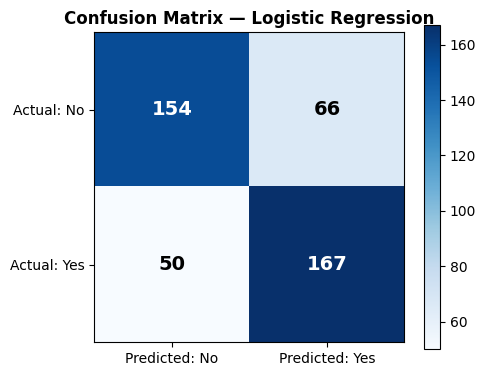

In [17]:
cm_lr = confusion_matrix(y_test, lr_pred)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm_lr, cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks([0,1]); ax.set_xticklabels(['Predicted: No', 'Predicted: Yes'])
ax.set_yticks([0,1]); ax.set_yticklabels(['Actual: No', 'Actual: Yes'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_lr[i,j]), ha='center', va='center',
                color='white' if cm_lr[i,j] > cm_lr.max()/2 else 'black',
                fontsize=14, fontweight='bold')
ax.set_title('Confusion Matrix — Logistic Regression', fontweight='bold')
plt.tight_layout()
plt.show()

### 6.5 ROC Curve

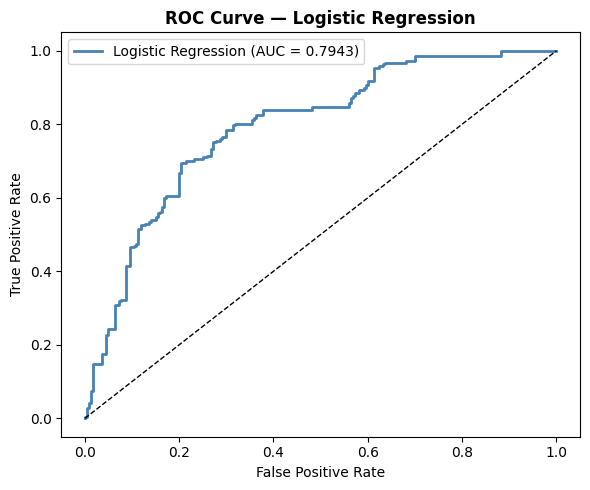

In [18]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, color='steelblue', lw=2, label=f'Logistic Regression (AUC = {auc_lr:.4f})')
plt.plot([0,1],[0,1],'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Logistic Regression', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

---
## 7. Model 2 — Random Forest Classifier

Random Forest is an ensemble method that trains many decision trees on random subsets of the data and features (bagging), then aggregates their votes. It handles non-linear relationships and provides feature importance rankings.

### 7.1 Hyperparameter Tuning (GridSearchCV)

In [19]:
rf_params = {
    'n_estimators':    [50, 100, 200],
    'max_depth':       [None, 5, 10],
    'min_samples_split': [2, 5]
}

gs_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params, cv=5, scoring='accuracy', n_jobs=-1
)
gs_rf.fit(X_train, y_train)

print('Best parameters:', gs_rf.best_params_)
print(f'Best CV accuracy: {gs_rf.best_score_:.4f}')

Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV accuracy: 0.9530


### 7.2 Train Best Model

In [20]:
rf_best = gs_rf.best_estimator_
rf_pred = rf_best.predict(X_test)
rf_prob = rf_best.predict_proba(X_test)[:, 1]

print(f'Test Accuracy: {accuracy_score(y_test, rf_pred):.4f}')
print()
print(classification_report(y_test, rf_pred, target_names=['No Disease', 'Heart Disease']))

Test Accuracy: 0.9268

               precision    recall  f1-score   support

   No Disease       0.93      0.93      0.93       220
Heart Disease       0.93      0.93      0.93       217

     accuracy                           0.93       437
    macro avg       0.93      0.93      0.93       437
 weighted avg       0.93      0.93      0.93       437



### 7.3 5-Fold Cross-Validation

In [21]:
pipe_rf = Pipeline([
    ('rf', RandomForestClassifier(n_estimators=200, random_state=42))
])
cv_rf = cross_val_score(pipe_rf, X, y, cv=5, scoring='accuracy')
print(f'CV Scores: {cv_rf.round(4)}')
print(f'Mean: {cv_rf.mean():.4f}  |  Std: {cv_rf.std():.4f}')

CV Scores: [1.     1.     0.9954 0.5917 0.9083]
Mean: 0.8991  |  Std: 0.1576


### 7.4 Confusion Matrix

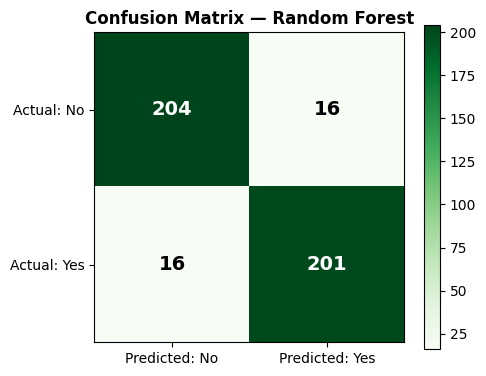

In [22]:
cm_rf = confusion_matrix(y_test, rf_pred)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm_rf, cmap='Greens')
plt.colorbar(im, ax=ax)
ax.set_xticks([0,1]); ax.set_xticklabels(['Predicted: No', 'Predicted: Yes'])
ax.set_yticks([0,1]); ax.set_yticklabels(['Actual: No', 'Actual: Yes'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_rf[i,j]), ha='center', va='center',
                color='white' if cm_rf[i,j] > cm_rf.max()/2 else 'black',
                fontsize=14, fontweight='bold')
ax.set_title('Confusion Matrix — Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

### 7.5 ROC Curve

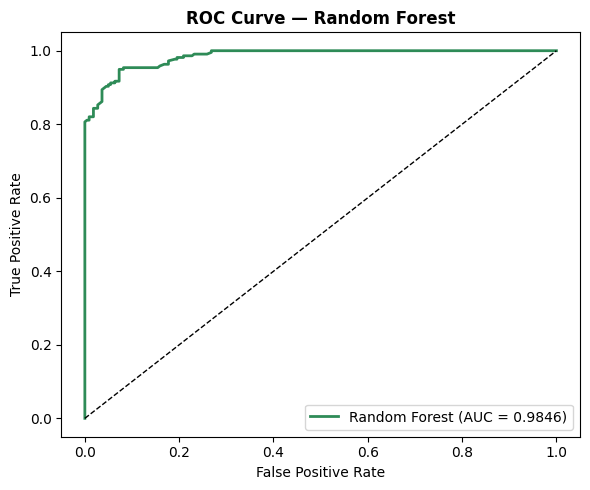

In [23]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(6, 5))
plt.plot(fpr_rf, tpr_rf, color='seagreen', lw=2, label=f'Random Forest (AUC = {auc_rf:.4f})')
plt.plot([0,1],[0,1],'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Random Forest', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

### 7.6 Feature Importance

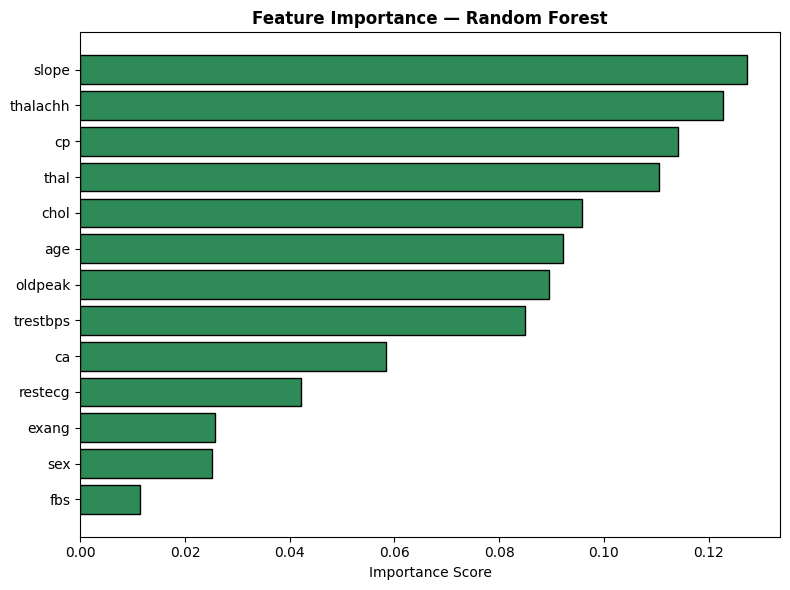

slope       0.1273
thalachh    0.1228
cp          0.1141
thal        0.1104
chol        0.0957
age         0.0923
oldpeak     0.0896
trestbps    0.0849
ca          0.0585
restecg     0.0422
exang       0.0257
sex         0.0252
fbs         0.0114
dtype: float64


In [24]:
importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importances.index, importances.values, color='seagreen', edgecolor='black')
plt.xlabel('Importance Score')
plt.title('Feature Importance — Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(4))

---
## 8. Model Comparison

In [25]:
results = {
    'Logistic Regression': {
        'pred': lr_pred, 'prob': lr_prob,
        'fpr': fpr_lr, 'tpr': tpr_lr, 'auc': auc_lr, 'color': 'steelblue'
    },
    'Random Forest': {
        'pred': rf_pred, 'prob': rf_prob,
        'fpr': fpr_rf, 'tpr': tpr_rf, 'auc': auc_rf, 'color': 'seagreen'
    }
}

comparison = []
for name, r in results.items():
    comparison.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, r['pred']), 4),
        'Precision': round(precision_score(y_test, r['pred']), 4),
        'Recall':    round(recall_score(y_test, r['pred']), 4),
        'F1 Score':  round(f1_score(y_test, r['pred']), 4),
        'AUC-ROC':   round(roc_auc_score(y_test, r['prob']), 4),
    })

comp_df = pd.DataFrame(comparison).set_index('Model')
print(comp_df.to_string())

                     Accuracy  Precision  Recall  F1 Score  AUC-ROC
Model                                                              
Logistic Regression    0.7346     0.7167  0.7696    0.7422   0.7943
Random Forest          0.9268     0.9263  0.9263    0.9263   0.9846


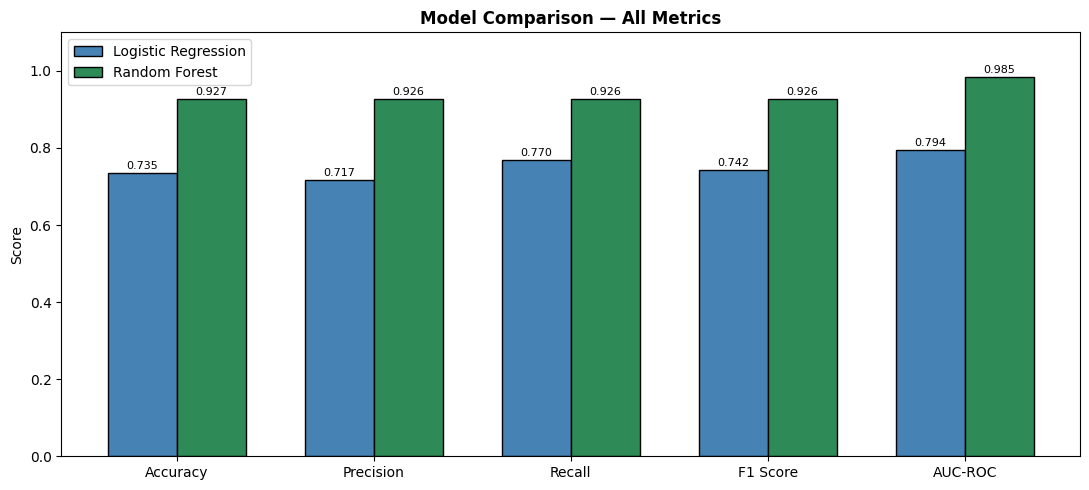

In [26]:
# Side-by-side metric bar chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - width/2, comp_df.loc['Logistic Regression', metrics], width,
               label='Logistic Regression', color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, comp_df.loc['Random Forest', metrics], width,
               label='Random Forest', color='seagreen', edgecolor='black')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — All Metrics', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

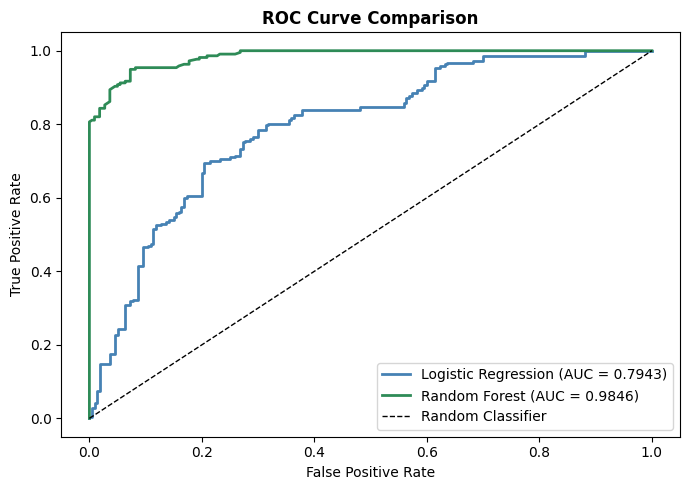

In [27]:
# Combined ROC Curve
plt.figure(figsize=(7, 5))
for name, r in results.items():
    plt.plot(r['fpr'], r['tpr'], lw=2, color=r['color'],
             label=f"{name} (AUC = {r['auc']:.4f})")
plt.plot([0,1],[0,1],'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

---
## 9. Conclusion

**Random Forest outperforms Logistic Regression on every metric:**

| Metric | Logistic Regression | Random Forest |
|---|---|---|
| Accuracy | 0.7346 | 0.9268 |
| Precision | 0.7167 | 0.9263 |
| Recall | 0.7696 | 0.9263 |
| F1 Score | 0.7422 | 0.9263 |
| AUC-ROC | 0.7943 | 0.9846 |

Random Forest achieves ~19% higher accuracy and a much stronger AUC of 0.9846. Its ability to capture non-linear relationships between clinical features (e.g. how age interacts with ST depression and chest pain type) gives it a significant advantage over the linear Logistic Regression model on this dataset.

The most predictive features according to Random Forest are: **slope, thalachh (max heart rate), cp (chest pain type), thal, and chol** — consistent with clinical knowledge about cardiovascular risk factors.